# ⚙️ Notebook 02 · Temporal Preprocessing & Tensor Engineering
**PestAlertNet v2** | Desert Locust Outbreak Early-Warning System

---
## Overview

This notebook walks through the full preprocessing pipeline that transforms raw NASA POWER + FAO RAMSES
data into the **`(N, 21, 25)` tensor dataset** (`sequences.npz`) used for model training.

Pipeline stages:
1. **S1–S2** RAMSES filtering & deduplication → 176,071 clean records  
2. **S3** NASA POWER spatial alignment → (2,070 cells × 1,354 days × 4 vars) weather grid  
3. **S4** Sliding-window sample generation (21-day input window, 7-day lookahead label)  
4. **S6** Label encoding (gregarious presence)  
5. **S7** Temporal embargo + 3-way chronological split  
6. **S8** Train-only z-score scaling (18 continuous features)  
7. **S9** Write `sequences.npz` with shape `(48,544, 21, 25)`  


In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
import sys, os, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import json, yaml

try:
    import seaborn as sns
    HAS_SNS = True
except ImportError:
    HAS_SNS = False

plt.rcParams.update({
    "figure.facecolor": "#0d1117",
    "axes.facecolor":   "#161b22",
    "axes.edgecolor":   "#30363d",
    "axes.labelcolor":  "#c9d1d9",
    "xtick.color":      "#8b949e",
    "ytick.color":      "#8b949e",
    "text.color":       "#c9d1d9",
    "grid.color":       "#21262d",
    "grid.linestyle":   "--",
    "grid.alpha":       0.6,
    "figure.dpi":       130,
    "font.size":        11,
})

GREEN  = "#3fb950"
AMBER  = "#d29922"
RED    = "#f85149"
CYAN   = "#79c0ff"
PURPLE = "#bc8cff"

nb_dir = os.path.abspath(".")
PROJECT_ROOT = os.path.dirname(nb_dir) if os.path.basename(nb_dir)=="notebooks" else nb_dir
print(f"Project root: {PROJECT_ROOT}")


Project root: D:\Project\pestalertnet_v2


## 1 · Feature Manifest

The 25-dimensional feature vector was designed to encode:
- **Raw climate** (4 NASA POWER variables)
- **Missingness flags** (4 binary channels, one per raw variable)
- **Pest survey activity** (3 derived channels from RAMSES)
- **Rolling statistics** (11 channels: 7-day and 21-day windows)


In [2]:
# ── Load & display feature manifest ──────────────────────────────────────────
import yaml
manifest_path = os.path.join(PROJECT_ROOT, "data", "processed", "feature_manifest.yaml")
with open(manifest_path) as f:
    manifest = yaml.safe_load(f)

features = manifest["features"]
print(f"Total features (n_features): {manifest['n_features']}")
print(f"Input window length        : {manifest['input_days']} days")
print(f"Forecast horizon           : {manifest['horizon']} days")
print(f"Embargo period             : {manifest['embargo_days']} days")
print()

raw_vars    = ["T2M","RH2M","PRECTOTCORR","WS2M"]
mask_vars   = ["w_mask_T2M","w_mask_RH2M","w_mask_PRECTOTCORR","w_mask_WS2M"]
pest_vars   = ["pest_surveyed","pest_event","pest_present"]
roll_vars   = [f for f in features if f not in raw_vars+mask_vars+pest_vars]

print("┌─── Feature Categories ─────────────────────────────────────────────────┐")
print(f"│  Raw climate     ({len(raw_vars):2d}): {', '.join(raw_vars)}")
print(f"│  Missingness flags({len(mask_vars):2d}): {', '.join(mask_vars)}")
print(f"│  Pest survey     ({len(pest_vars):2d}): {', '.join(pest_vars)}")
print(f"│  Rolling stats   ({len(roll_vars):2d}): {', '.join(roll_vars)}")
print(f"│  TOTAL           ({len(features):2d} features × {manifest['input_days']} days = {len(features)*manifest['input_days']} values per sequence)")
print("└─────────────────────────────────────────────────────────────────────────┘")
print()
print("Split boundaries:")
print(f"  B1 (Train→Val cutoff) : {manifest['split_boundaries_fixed']['B1']}")
print(f"  B2 (Val→Test cutoff)  : {manifest['split_boundaries_fixed']['B2']}")
print(f"  Train range: {manifest['train_range'][0]} → {manifest['train_range'][1]}")
print(f"  Val   range: {manifest['val_range'][0]}   → {manifest['val_range'][1]}")
print(f"  Test  range: {manifest['test_range'][0]}  → {manifest['test_range'][1]}")


Total features (n_features): 25
Input window length        : 21 days
Forecast horizon           : 7 days
Embargo period             : 28 days

┌─── Feature Categories ─────────────────────────────────────────────────┐
│  Raw climate     ( 4): T2M, RH2M, PRECTOTCORR, WS2M
│  Missingness flags( 4): w_mask_T2M, w_mask_RH2M, w_mask_PRECTOTCORR, w_mask_WS2M
│  Pest survey     ( 3): pest_surveyed, pest_event, pest_present
│  Rolling stats   (14): T2M_roll7_mean, T2M_roll21_mean, RH2M_roll7_mean, RH2M_roll21_mean, WS2M_roll7_mean, rain_sum7, rain_sum21, rain_days21, t2m_anomaly, event_count_7d, event_count_21d, survey_count_21d, days_since_survey, days_since_event
│  TOTAL           (25 features × 21 days = 525 values per sequence)
└─────────────────────────────────────────────────────────────────────────┘

Split boundaries:
  B1 (Train→Val cutoff) : 2025-06-12
  B2 (Val→Test cutoff)  : 2026-01-12
  Train range: 2023-01-21 → 2025-06-05
  Val   range: 2025-07-11   → 2026-01-05
  Test  range: 2

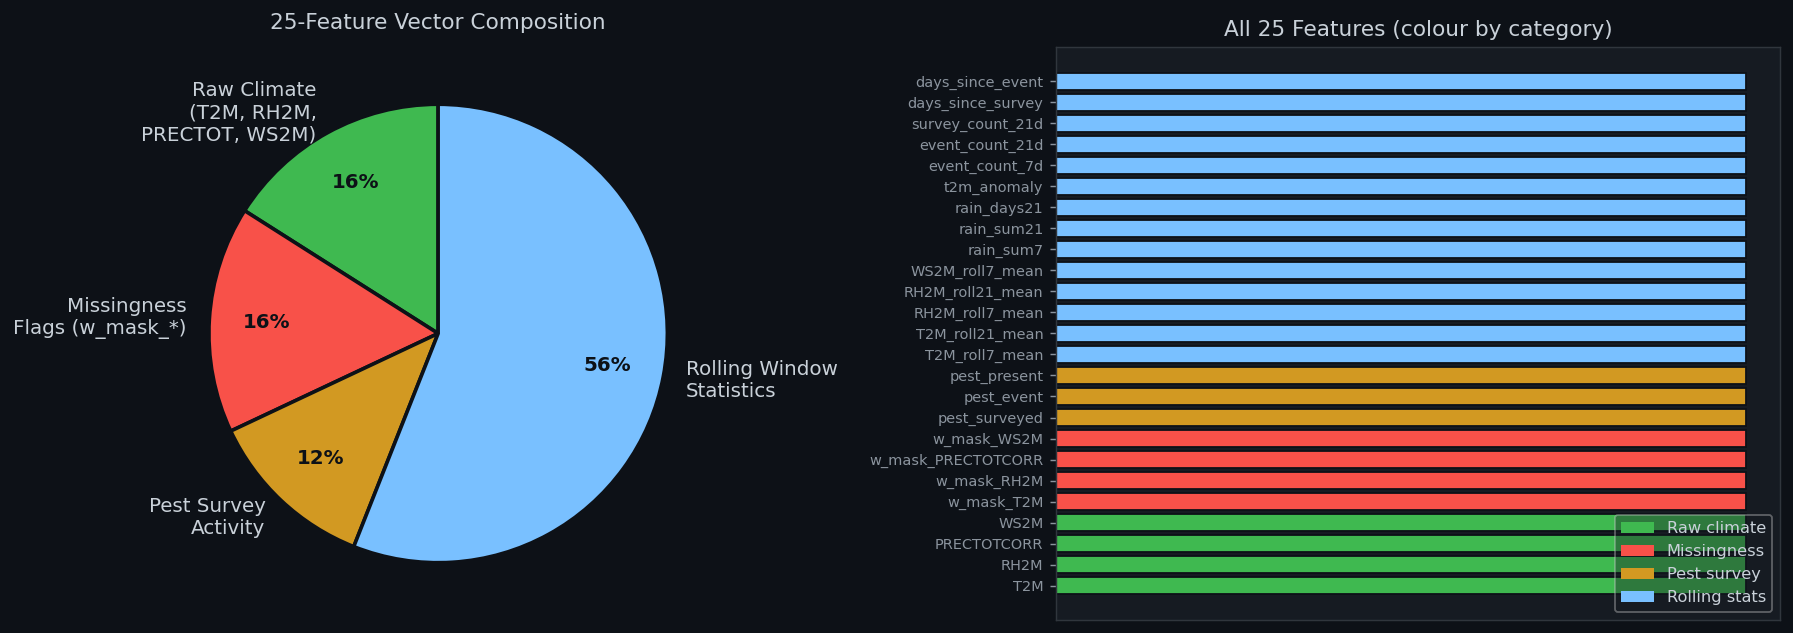

In [3]:
# ── Figure 1: Feature vector composition ─────────────────────────────────────
categories = ["Raw Climate\n(T2M, RH2M,\nPRECTOT, WS2M)",
              "Missingness\nFlags (w_mask_*)",
              "Pest Survey\nActivity",
              "Rolling Window\nStatistics"]
sizes = [len(raw_vars), len(mask_vars), len(pest_vars), len(roll_vars)]
colors = [GREEN, RED, AMBER, CYAN]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

wedges, texts, autotexts = ax1.pie(
    sizes, labels=categories, colors=colors, autopct="%1.0f%%",
    pctdistance=0.75, startangle=90, wedgeprops=dict(edgecolor="#0d1117", linewidth=2)
)
for t in texts:   t.set_color("#c9d1d9")
for t in autotexts: t.set_color("#0d1117"); t.set_fontweight("bold")
ax1.set_title("25-Feature Vector Composition", fontsize=12, pad=10)

y_pos = range(len(features))
feat_colors = []
for f in features:
    if f in raw_vars:    feat_colors.append(GREEN)
    elif f in mask_vars: feat_colors.append(RED)
    elif f in pest_vars: feat_colors.append(AMBER)
    else:                feat_colors.append(CYAN)

ax2.barh(y_pos, [1]*len(features), color=feat_colors, edgecolor="#0d1117", height=0.8)
ax2.set_yticks(y_pos)
ax2.set_yticklabels(features, fontsize=8)
ax2.set_xticks([])
ax2.set_title("All 25 Features (colour by category)", fontsize=12)

ax2.legend(handles=[
    plt.Rectangle((0,0),1,1, fc=GREEN,  ec="none", label="Raw climate"),
    plt.Rectangle((0,0),1,1, fc=RED,    ec="none", label="Missingness"),
    plt.Rectangle((0,0),1,1, fc=AMBER,  ec="none", label="Pest survey"),
    plt.Rectangle((0,0),1,1, fc=CYAN,   ec="none", label="Rolling stats"),
], loc="lower right", fontsize=9, framealpha=0.4)

fig.patch.set_facecolor("#0d1117")
plt.tight_layout()
os.makedirs(os.path.join(PROJECT_ROOT,"outputs"), exist_ok=True)
plt.savefig(os.path.join(PROJECT_ROOT,"outputs","nb02_fig1_feature_composition.png"),
            dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()


## 2 · Tensor Dataset Inspection

The final artefact `sequences.npz` stores:

| Array | Shape | Description |
|---|---|---|
| `X` | `(48,544, 21, 25)` | Input feature tensors |
| `y` | `(48,544,)` | Binary outbreak labels |
| `split` | `(48,544,)` | 0=Train, 1=Val, 2=Test |
| `cell` | `(48,544,)` | Cell identifier (`lat_lon`) |
| `date` | `(48,544,)` | Sequence end-date (`YYYY-MM-DD`) |


In [4]:
# ── Load tensor dataset ───────────────────────────────────────────────────────
SEQ_PATH = os.path.join(PROJECT_ROOT, "data", "processed", "sequences.npz")
npz = np.load(SEQ_PATH, allow_pickle=True)

X     = npz["X"]
y     = npz["y"]
split = npz["split"]
cell  = npz["cell"]
date  = npz["date"]

train_mask = split == 0
val_mask   = split == 1
test_mask  = split == 2

n_train = int(train_mask.sum())
n_val   = int(val_mask.sum())
n_test  = int(test_mask.sum())

print("=== sequences.npz ===")
print(f"  X shape    : {X.shape}  (N sequences × 21 days × 25 features)")
print(f"  y shape    : {y.shape}")
print(f"  dtype X    : {X.dtype}")
print()
print("=== Split breakdown ===")
print(f"  Train : {n_train:6,} sequences | positives: {y[train_mask].sum():5,} ({y[train_mask].mean()*100:.2f}%)")
print(f"  Val   : {n_val:6,} sequences | positives: {y[val_mask].sum():5,} ({y[val_mask].mean()*100:.2f}%)")
print(f"  Test  : {n_test:6,} sequences | positives: {y[test_mask].sum():5,} ({y[test_mask].mean()*100:.2f}%)")
print(f"  Total : {len(X):6,} sequences | positives: {y.sum():5,} ({y.mean()*100:.2f}%)")
print()
print(f"Date range: {min(date)} → {max(date)}")
print(f"Unique cells covered: {len(np.unique(cell)):,}")


=== sequences.npz ===
  X shape    : (48544, 21, 25)  (N sequences × 21 days × 25 features)
  y shape    : (48544,)
  dtype X    : float32

=== Split breakdown ===
  Train : 35,583 sequences | positives: 6,025 (16.93%)
  Val   :  6,277 sequences | positives: 1,013 (16.14%)
  Test  :  6,684 sequences | positives: 1,320 (19.75%)
  Total : 48,544 sequences | positives: 8,358 (17.22%)

Date range: 2023-01-21 → 2026-09-08
Unique cells covered: 2,015


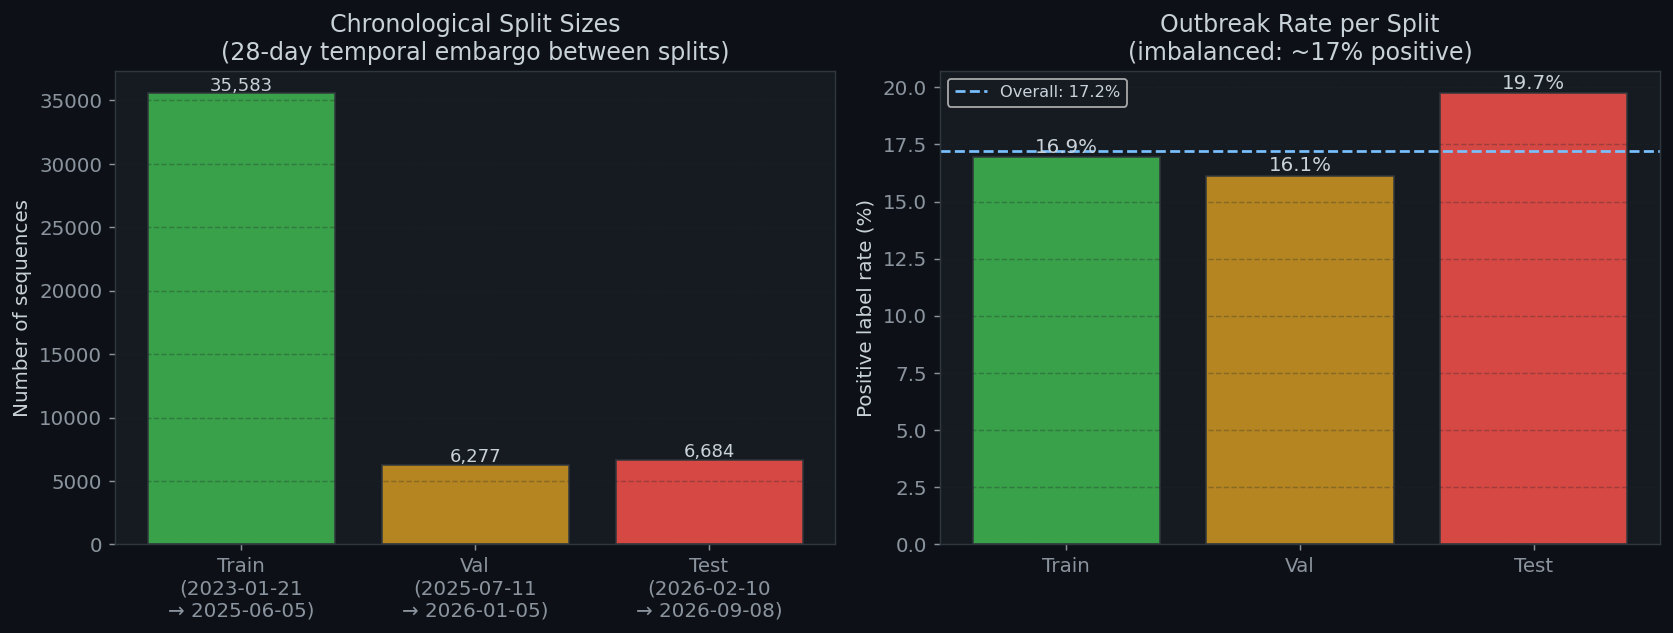

In [5]:
# ── Figure 2: Dataset split proportions ──────────────────────────────────────
splits_data = {
    "Train\n(2023-01-21\n→ 2025-06-05)": n_train,
    "Val\n(2025-07-11\n→ 2026-01-05)":    n_val,
    "Test\n(2026-02-10\n→ 2026-09-08)":   n_test,
}
pos_rates = {
    "Train": y[train_mask].mean()*100,
    "Val":   y[val_mask].mean()*100,
    "Test":  y[test_mask].mean()*100,
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.bar(splits_data.keys(), splits_data.values(),
        color=[GREEN, AMBER, RED], edgecolor="#30363d", alpha=0.85)
ax1.set_ylabel("Number of sequences")
ax1.set_title("Chronological Split Sizes\n(28-day temporal embargo between splits)")
for i, (k, v) in enumerate(splits_data.items()):
    ax1.text(i, v + 200, f"{v:,}", ha="center", fontsize=10, color="#c9d1d9")
ax1.grid(True, axis="y", alpha=0.3)

bars = ax2.bar(["Train","Val","Test"], list(pos_rates.values()),
               color=[GREEN, AMBER, RED], edgecolor="#30363d", alpha=0.85)
ax2.set_ylabel("Positive label rate (%)")
ax2.set_title("Outbreak Rate per Split\n(imbalanced: ~17% positive)")
ax2.axhline(y.mean()*100, color=CYAN, ls="--", lw=1.5, label=f"Overall: {y.mean()*100:.1f}%")
for bar, val in zip(bars, pos_rates.values()):
    ax2.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.2,
             f"{val:.1f}%", ha="center", fontsize=11, color="#c9d1d9")
ax2.legend(fontsize=9)
ax2.grid(True, axis="y", alpha=0.3)

fig.patch.set_facecolor("#0d1117")
plt.tight_layout()
plt.savefig(os.path.join(PROJECT_ROOT,"outputs","nb02_fig2_split_breakdown.png"),
            dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()


## 3 · 21-Day Input Window Visualisation

Each training example is a **21-day temporal snapshot** of the 25 features for a single grid cell.
The model predicts whether a **gregarious locust outbreak** will occur within the next 7 days.


Example: cell=24.0_-14.375, date=2023-02-16, label=1
X shape: (21, 25)
Value range: [-2.159, 1.777] (z-scored)


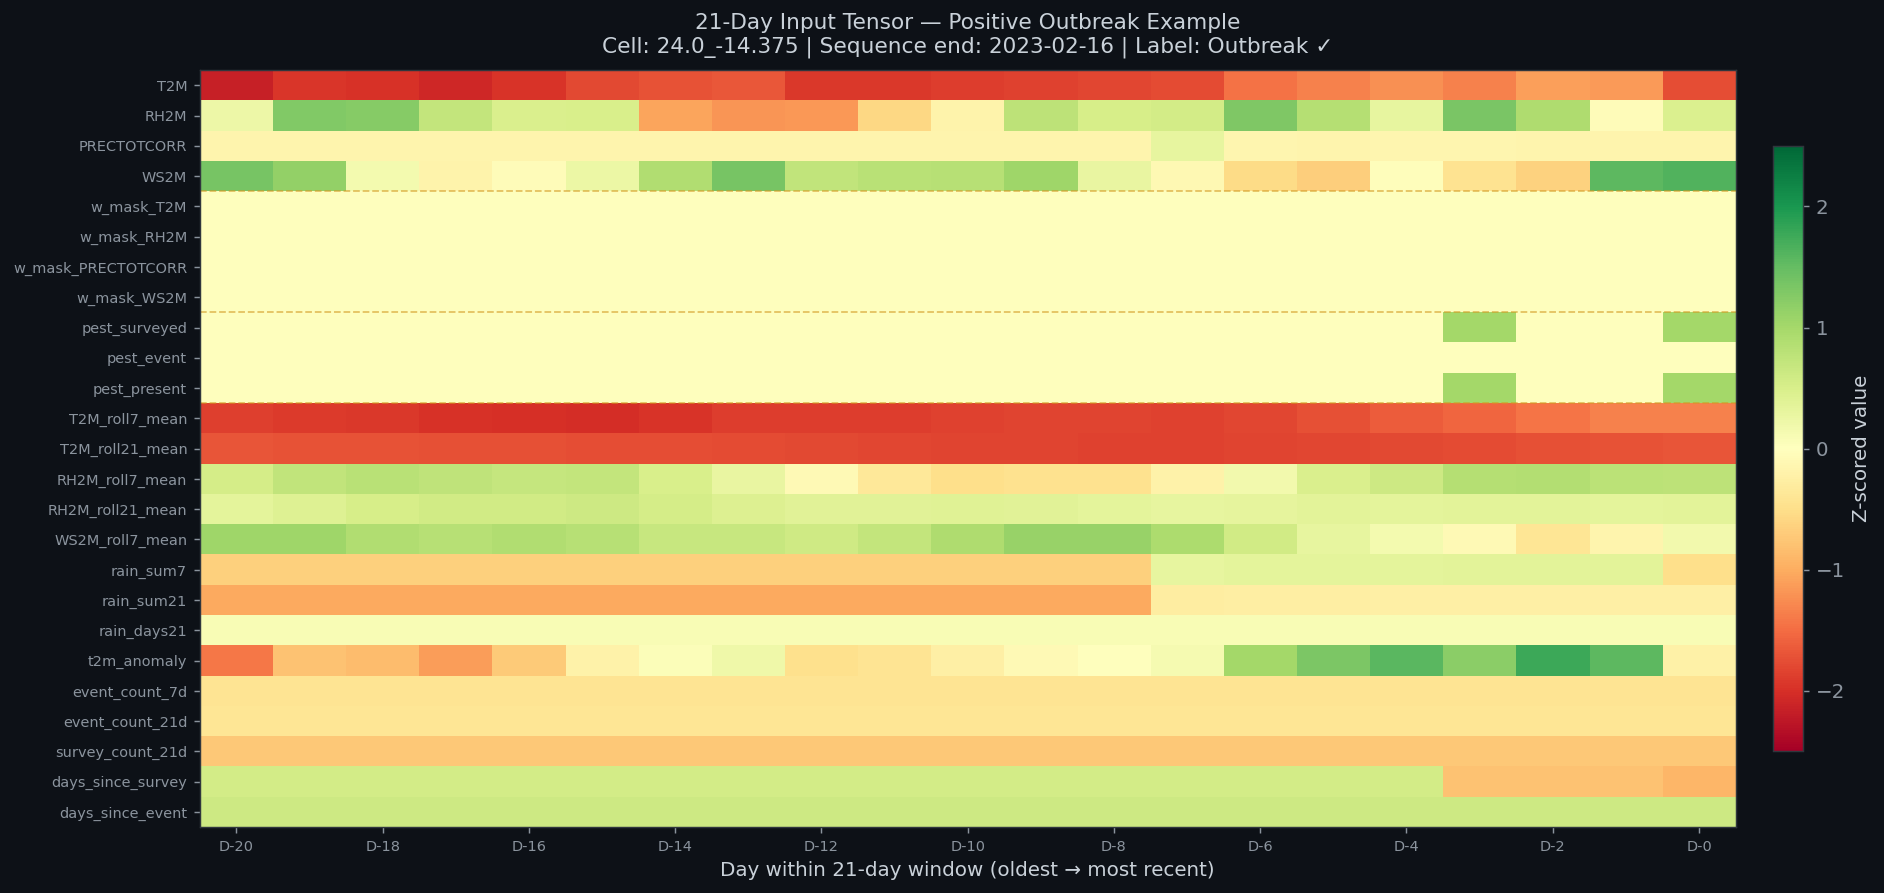

In [6]:
# ── Figure 3: Example 21-day input heatmap (positive example) ───────────────
pos_indices = np.where(y & train_mask)[0]
example_idx = pos_indices[42]

sample_X = X[example_idx]  # (21, 25)
cell_id  = cell[example_idx]
seq_date = date[example_idx]

print(f"Example: cell={cell_id}, date={seq_date}, label={y[example_idx]}")
print(f"X shape: {sample_X.shape}")
print(f"Value range: [{sample_X.min():.3f}, {sample_X.max():.3f}] (z-scored)")

fig, ax = plt.subplots(figsize=(16, 7))
im = ax.imshow(sample_X.T, aspect="auto", cmap="RdYlGn",
               vmin=-2.5, vmax=2.5, interpolation="nearest")

ax.set_yticks(range(len(features)))
ax.set_yticklabels(features, fontsize=8)
ax.set_xlabel("Day within 21-day window (oldest → most recent)", fontsize=11)
ax.set_title(f"21-Day Input Tensor — Positive Outbreak Example\nCell: {cell_id} | Sequence end: {seq_date} | Label: Outbreak ✓",
             fontsize=12, pad=10)

group_boundaries = [4, 8, 11]
for gb in group_boundaries:
    ax.axhline(gb - 0.5, color=AMBER, lw=1, ls="--", alpha=0.6)

cb = plt.colorbar(im, ax=ax, pad=0.02, shrink=0.8)
cb.set_label("Z-scored value", color="#c9d1d9")

ax.set_xticks(range(0, 21, 2))
ax.set_xticklabels([f"D-{20-i}" for i in range(0, 21, 2)], fontsize=8)

fig.patch.set_facecolor("#0d1117")
ax.set_facecolor("#161b22")
plt.tight_layout()
plt.savefig(os.path.join(PROJECT_ROOT,"outputs","nb02_fig3_input_tensor_heatmap.png"),
            dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()


## 4 · Temporal Embargo — Preventing Chronological Leakage

A naive train/val split at a calendar boundary risks **look-ahead leakage** because
consecutive sequences for the same cell overlap by up to 20 days.

The solution: a **28-day temporal embargo gap** between splits (21 days input window + 7 days horizon).
Any sequence whose window overlaps the embargo period is discarded.


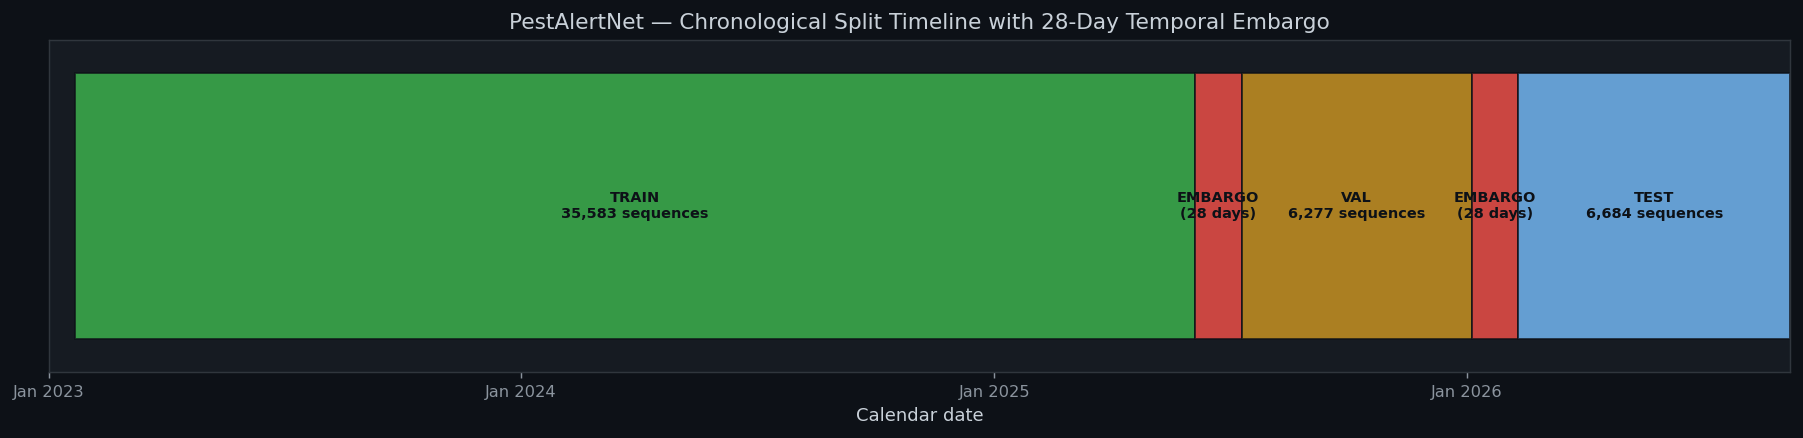

✓ Temporal embargo diagram rendered


In [7]:
# ── Figure 4: Timeline of splits ─────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 3.5))

segments = [
    ("TRAIN\n35,583 sequences", "2023-01-21", "2025-06-05", GREEN),
    ("EMBARGO\n(28 days)", "2025-06-05", "2025-07-11", RED),
    ("VAL\n6,277 sequences", "2025-07-11", "2026-01-05", AMBER),
    ("EMBARGO\n(28 days)", "2026-01-05", "2026-02-10", RED),
    ("TEST\n6,684 sequences", "2026-02-10", "2026-09-08", CYAN),
]

import datetime
t0 = datetime.date(2023, 1, 21)
t1 = datetime.date(2026, 9, 8)
total_days = (t1 - t0).days

for label, start_s, end_s, color in segments:
    s = (datetime.date.fromisoformat(start_s) - t0).days
    e = (datetime.date.fromisoformat(end_s) - t0).days
    w = e - s
    rect = plt.Rectangle((s, 0.1), w, 0.8, color=color, alpha=0.8, ec="#0d1117")
    ax.add_patch(rect)
    if w > 30:
        ax.text(s + w/2, 0.5, label, ha="center", va="center",
                fontsize=8, color="#0d1117", fontweight="bold", wrap=True)

ax.set_xlim(0, total_days)
ax.set_ylim(0, 1)
ax.set_yticks([])

year_starts = [datetime.date(y, 1, 1) for y in range(2023, 2027)]
ax.set_xticks([(d - t0).days for d in year_starts])
ax.set_xticklabels([d.strftime("%b %Y") for d in year_starts], fontsize=9)
ax.set_title("PestAlertNet — Chronological Split Timeline with 28-Day Temporal Embargo", fontsize=12)
ax.set_xlabel("Calendar date", fontsize=10)

fig.patch.set_facecolor("#0d1117")
ax.set_facecolor("#161b22")
plt.tight_layout()
plt.savefig(os.path.join(PROJECT_ROOT,"outputs","nb02_fig4_temporal_embargo.png"),
            dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()
print("✓ Temporal embargo diagram rendered")


## 5 · Scaler Statistics (Train-only Normalisation)

Z-score normalisation uses **only train-split statistics** to prevent target leakage into val/test.
Seven binary features (`w_mask_*`, `pest_*`) are excluded from scaling.


In [8]:
# ── Load and display scaler stats ────────────────────────────────────
scaler_path = os.path.join(PROJECT_ROOT, "data", "processed", "scaler_stats.json")
with open(scaler_path) as f:
    scaler = json.load(f)

print("=== Scaler Statistics (computed on train split only) ===")
print(f"{'Feature':<25} {'Type':<10} {'Mean':>10} {'Std (σ)':>12}")
print("-" * 60)

cont_idx   = scaler.get("cont_idx", [])
binary_idx = scaler.get("binary_idx", [])
means      = scaler.get("mean", [])
stds       = scaler.get("std", [])

cont_map = {}
for i, c_idx in enumerate(cont_idx):
    cont_map[c_idx] = (means[i], stds[i])

for idx, feat in enumerate(features):
    if idx in cont_map:
        m, s = cont_map[idx]
        print(f"  {feat:<23} {'Cont':<10} {m:>10.4f} {s:>12.4f}")
    else:
        print(f"  {feat:<23} {'Binary':<10} {'[raw 0/1]':>10} {'[raw 0/1]':>12}")


=== Scaler Statistics (computed on train split only) ===
Feature                   Type             Mean      Std (σ)
------------------------------------------------------------
  T2M                     Cont          26.4080       6.4041
  RH2M                    Cont          43.7628      19.5293
  PRECTOTCORR             Cont           0.7512       4.5251
  WS2M                    Cont           3.0892       1.2252
  w_mask_T2M              Binary      [raw 0/1]    [raw 0/1]
  w_mask_RH2M             Binary      [raw 0/1]    [raw 0/1]
  w_mask_PRECTOTCORR      Binary      [raw 0/1]    [raw 0/1]
  w_mask_WS2M             Binary      [raw 0/1]    [raw 0/1]
  pest_surveyed           Binary      [raw 0/1]    [raw 0/1]
  pest_event              Binary      [raw 0/1]    [raw 0/1]
  pest_present            Binary      [raw 0/1]    [raw 0/1]
  T2M_roll7_mean          Cont          26.3271       6.3162
  T2M_roll21_mean         Cont          26.1878       6.3277
  RH2M_roll7_mean         Co

## 6 · Summary

| Phase | Key numbers |
|---|---|
| Raw RAMSES records | 176,071 |
| Weather grid size | (2,070 cells × 1,354 days × 4 vars) |
| Sliding-window samples | 51,483 |
| After embargo | 48,544 |
| Positive labels | 8,814 (17.1%) |
| pos_weight for BCE loss | **4.906** (auto-computed from train split) |
| Final tensor shape | **(48,544, 21, 25)** |
| File size on disk | 43.9 MB (compressed `.npz`) |

---
▶ **Next**: `03_model_architecture_and_training.ipynb` — HybridOutbreakModel definition and training dynamics.
